# 06 · Customer segmentation
Two approaches, compared:
1. **Business segments** (value deciles of early revenue): simple, explainable, already used in the dashboard.
2. **Optional extension: K-means behavioural clusters** on usage mix and spend. Its purpose is to find *how* customers use the network, which value tiers alone can't show. Clusters are not assumed to be meaningful until they are interpreted.

In [1]:
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.data_loader import get_engine, query, PROJECT_ROOT
from src import analysis as an
an.set_style()
pd.set_option("display.float_format", "{:,.2f}".format); pd.set_option("display.max_columns", 30)
engine = get_engine()
o = an.sql_output
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

In [2]:
cs = query(engine, """SELECT customer_id, customer_type, value_segment, avg_monthly_revenue, avg_data_mb, avg_voice_minutes,
       avg_sms, avg_transactions, tenure_months, churned FROM telco.v_customer_summary WHERE active_months >= 4""")
for c in ["avg_monthly_revenue", "avg_data_mb", "avg_voice_minutes", "avg_sms", "avg_transactions"]:
    cs[c] = cs[c].astype(float)
feat = pd.DataFrame({
    "log_revenue": np.log1p(cs.avg_monthly_revenue),
    "log_data_mb": np.log1p(cs.avg_data_mb),
    "log_voice_min": np.log1p(cs.avg_voice_minutes),
    "log_sms": np.log1p(cs.avg_sms),
    "purchases_per_month": cs.avg_transactions,
})
print(len(feat), "customers with >= 4 active months"); feat.describe().T[["mean", "std", "min", "max"]]

25711 customers with >= 4 active months


,mean,std,min,max
log_revenue,6.21,0.89,3.13,8.67
log_data_mb,7.51,1.52,3.39,10.66
log_voice_min,4.82,0.99,1.95,7.50
log_sms,3.46,0.43,1.79,4.72
purchases_per_month,3.13,0.85,1.00,6.75


**Feature choices.** Spend, data, voice and SMS describe *what* a customer uses, and purchase frequency describes *how* they buy. All are log-transformed (they are heavily skewed) and then **standardised**, because K-means uses Euclidean distance: without scaling, data MB, which runs into thousands, would dominate SMS counts. Tenure and churn are deliberately **left out**, so they can be used afterwards to check whether the clusters mean anything.

,k,inertia,silhouette
0,2,"67,641.07",0.51
1,3,"43,680.64",0.41
2,4,"30,224.00",0.49
3,5,"23,345.89",0.45
4,6,"20,798.69",0.43
5,7,"18,901.48",0.42
6,8,"17,378.52",0.42


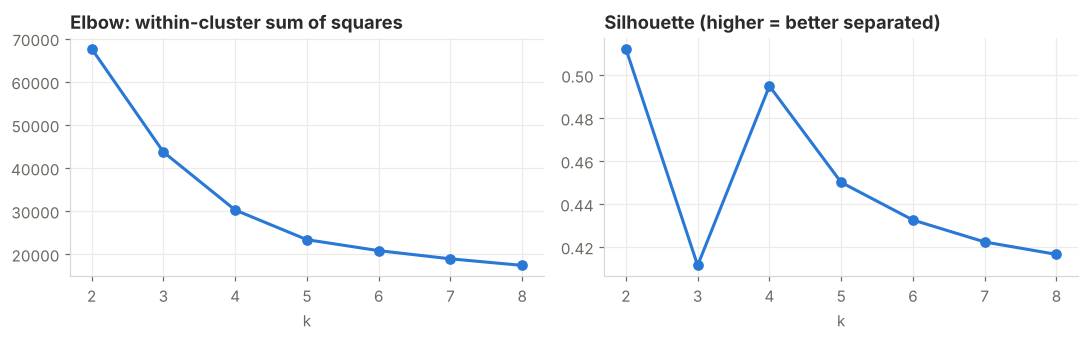

In [3]:
X = StandardScaler().fit_transform(feat)
rng = np.random.default_rng(0); sample = rng.choice(len(X), 6000, replace=False)
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X[sample], km.labels_[sample])})
sel = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(sel.k, sel.inertia, marker="o", color=an.PRIMARY); ax[0].set_title("Elbow: within-cluster sum of squares"); ax[0].set_xlabel("k")
ax[1].plot(sel.k, sel.silhouette, marker="o", color=an.PRIMARY); ax[1].set_title("Silhouette (higher = better separated)"); ax[1].set_xlabel("k")
fig.tight_layout(); an.save(fig, "kmeans_selection"); sel

In [4]:
# k = 2 scores well only because it splits light users from everyone else, which is too coarse to act on.
# Rule: among k = 3..6 (enough groups to target differently, few enough to explain), take the best silhouette.
cand = sel[sel.k.between(3, 6)]
K = int(cand.loc[cand.silhouette.idxmax(), "k"])
print("chosen k =", K)
km = KMeans(n_clusters=K, n_init=20, random_state=0).fit(X)
cs["cluster"] = km.labels_
prof = cs.assign(**feat).groupby("cluster").agg(customers=("customer_id", "count"), avg_revenue=("avg_monthly_revenue", "median"),
        data_mb=("avg_data_mb", "median"), voice_min=("avg_voice_minutes", "median"), sms=("avg_sms", "median"),
        purchases=("avg_transactions", "median"), postpaid_pct=("customer_type", lambda s: 100 * (s == "Postpaid").mean()),
        churned_pct=("churned", lambda s: 100 * s.mean())).round(1)
prof

chosen k = 4


,customers,avg_revenue,data_mb,voice_min,sms,purchases,postpaid_pct,churned_pct
cluster,,,,,,,,
0,4851,115.60,188.00,35.60,16.90,2.00,6.00,46.70
1,12929,658.00,"4,572.30",103.40,30.00,3.70,3.50,23.40
2,2492,"2,624.30","11,857.20",510.00,43.00,2.10,87.10,6.90
3,5439,513.20,550.90,344.20,51.60,3.30,5.00,24.30


In [5]:
def name(r):
    if r.postpaid_pct > 50: return "Business postpaid"
    if r.data_mb > 4000: return "Data-heavy prepaid"
    if r.voice_min > 250 and r.data_mb < 1000: return "Voice-first prepaid"
    if r.avg_revenue < 200: return "Light / occasional"
    return "Balanced prepaid"
prof["label"] = prof.apply(name, axis=1)
cs["cluster_label"] = cs.cluster.map(prof.label)
prof[["label", "customers", "avg_revenue", "data_mb", "voice_min", "purchases", "postpaid_pct", "churned_pct"]]

,label,customers,avg_revenue,data_mb,voice_min,purchases,postpaid_pct,churned_pct
cluster,,,,,,,,
0,Light / occasional,4851,115.60,188.00,35.60,2.00,6.00,46.70
1,Data-heavy prepaid,12929,658.00,"4,572.30",103.40,3.70,3.50,23.40
2,Business postpaid,2492,"2,624.30","11,857.20",510.00,2.10,87.10,6.90
3,Voice-first prepaid,5439,513.20,550.90,344.20,3.30,5.00,24.30


Labels are assigned from the medians, with the rules written in the code so anyone can check them. A cluster earns a business name only if its profile clearly differs from the others.

value_segment,Bronze (bottom 40%),Gold (next 20%),Platinum (top 10%),Silver (next 30%)
cluster_label,,,,
Business postpaid,0.40,8.10,87.50,3.90
Data-heavy prepaid,17.20,34.70,3.60,44.50
Light / occasional,99.70,0.00,0.00,0.20
Voice-first prepaid,45.30,12.40,0.50,41.80


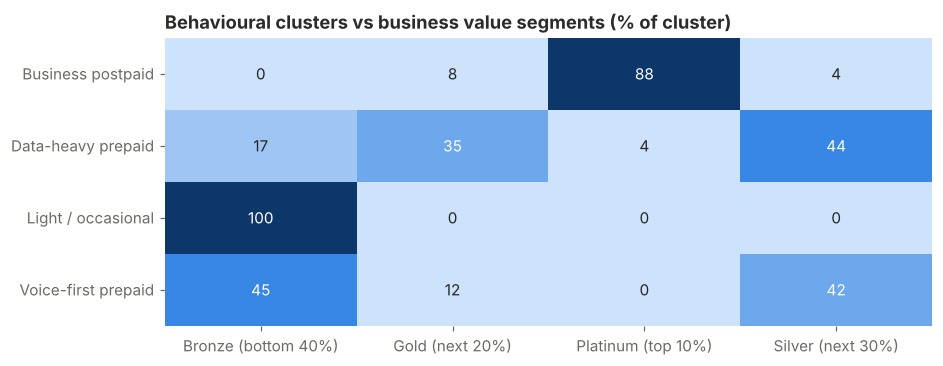

In [6]:
ct = pd.crosstab(cs.cluster_label, cs.value_segment, normalize="index").mul(100).round(1)
fig, ax = plt.subplots(figsize=(9, 3.4))
sns.heatmap(ct, annot=True, fmt=".0f", cmap=sns.color_palette(an.SEQ_BLUES, as_cmap=True), cbar=False, ax=ax)
ax.set_title("Behavioural clusters vs business value segments (% of cluster)"); ax.set_xlabel(""); ax.set_ylabel("")
an.save(fig, "clusters_vs_value_segments"); ct

**Clusters vs value segments.** Value tiers say *how much* customers spend, and clusters say *on what*. Data-heavy and voice-first customers can sit in the same value tier but need different offers: data bonuses for one group, voice or combo bundles for the other. That is the business case for keeping both views.

In [7]:
truth = pd.read_csv(PROJECT_ROOT / "data/synthetic/raw/_truth_archetypes.csv")
m = cs.merge(truth, on="customer_id")
print("Adjusted Rand Index, clusters vs generator archetypes:", round(adjusted_rand_score(m.archetype, m.cluster), 3))
pd.crosstab(m.cluster_label, m.archetype)

Adjusted Rand Index, clusters vs generator archetypes: 0.64


archetype,Business,Low-value occasional,Mainstream balanced,Voice-centric,Youth data-heavy
cluster_label,,,,,
Business postpaid,2136,0,313,1,42
Data-heavy prepaid,7,0,7232,12,5678
Light / occasional,0,4766,41,19,25
Voice-first prepaid,0,0,284,5155,0


**Validation (only possible because the data is synthetic).** The generator recorded each customer's hidden behavioural archetype. The Adjusted Rand Index compares the clusters with that truth: 0 would mean random agreement and 1 a perfect match. In real data there is no ground truth, and validation would rely on stability (re-running on samples) and on whether campaigns targeted by cluster perform better.

**Result:** an ARI of about 0.64. Four clusters recover the business, voice-centric and low-value archetypes almost perfectly. *Youth data-heavy* and *mainstream balanced* merge into one data-led cluster: they differ mainly in how much data they use, not in the shape of their usage. A fifth cluster would be justified only if the business wanted different offers for those two groups.

## Simple customer lifetime value (where the data supports it)

In [8]:
seg = o("q05_value_segments").query("value_segment != 'Unsegmented (too new)'").set_index("value_segment")
ch = o("q09_churn_by_segment").query("dim == 'value_segment'").set_index("grp").monthly_churn_pct / 100
rows = []
for s in seg.index:
    for margin in (0.45, 0.55, 0.65):
        rows.append({"value_segment": s, "contribution_margin": margin, "monthly_churn": ch[s],
                     "clv_kes": an.simple_clv(seg.loc[s, "avg_monthly_revenue_kes"] * margin, ch[s])})
clv = pd.DataFrame(rows).pivot_table(index="value_segment", columns="contribution_margin", values="clv_kes").round(-2)
clv.columns = [f"CLV @ {int(c*100)}% margin" for c in clv.columns]; clv

,CLV @ 45% margin,CLV @ 55% margin,CLV @ 65% margin
value_segment,,,
Bronze (bottom 40%),"3,500.00","4,300.00","5,100.00"
Gold (next 20%),"17,300.00","21,200.00","25,000.00"
Platinum (top 10%),"79,400.00","97,100.00","114,700.00"
Silver (next 30%),"12,600.00","15,400.00","18,200.00"


**CLV assumptions, stated plainly:** contribution margin is **not in the data**, so a 45–65% range is shown. Churn is assumed constant at each segment's average monthly rate, and there is a 1% monthly discount rate. The *ranking* (Platinum worth over 20× Bronze) is robust to those assumptions. The absolute shilling values are not, so they shouldn't be quoted without a finance-approved margin.